# Natural Language Processing



This project will give you practical experience using Natural Language Processing techniques. This project is in three parts:
- in part 1) you will use a dataset in a CSV file
- in part 2) you will use the Wikipedia API to directly access content
on Wikipedia.
- in part 3) you will make your notebook interactive


### Part 1)



- The CSV file is available at https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv
- The file contains a list of famous people and a brief overview.
- The goal of part 1) is to ...
  1. Pick one person from the list ( the reference person ) and output 10 other people who's overview are "closest" to the reference person in a Natural Language Processing sense
  1. Also output the sentiment of the overview of the reference person



### Part 2)



- For the same reference person that you chose in Part 1), use the Wikipedia API to access the whole content of the reference person's Wikipedia page.
- The goal of Part 2) is to ...
  1. Print out the text of the Wikipedia article for the reference person
  1. Determine the sentiment of the text of the Wikipedia page for the reference person
  1. Collect the text of the Wikipedia pages from the 10 nearest neighbors from Part 1)
  1. Determine the nearness ranking of these 10 people to your reference person based on their entire Wikipedia page
  1. Compare, i.e. plot,  the nearest ranking from Step 1) with the Wikipedia page nearness ranking.  A difference of the rank is one means of comparison.



### Part 3)


Make an interactive notebook where a user can choose or enter a name and the notebook displays the 10 closest individuals.

In addition to presenting the project slides, at the end of the presentation each student will demonstrate their code using a famous person suggested by the other students that exists in the DBpedia set.


## Data Collection

### Import

In [6]:
import duckdb
import pandas as pd
import os
import numpy as np
from google.colab import userdata


# TextBlob: cleans text (singularize) and scores sentiment
from textblob import TextBlob, Word

# TfidfVectorizer: turns each overview into a row of numbers (one column per word)
from sklearn.feature_extraction.text import TfidfVectorizer

# NearestNeighbors: finds the rows (people) closest to a reference row
from sklearn.neighbors import NearestNeighbors



## Convert CSV to Parquet

In [7]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'

In [8]:
# File name without the extension: 'NLP'
base_file = url.split("/")[-1].split(".")[0]
base_file

'NLP'

In [9]:
# Read the remote CSV and write it straight to a local parquet file (lesson 102's ETL step)
# No all_varchar here: DuckDB auto-detects types, so number columns stay numbers
con = duckdb.connect()
con.execute(f"""
    COPY (
        SELECT *
        FROM read_csv('{url}')
    )
    TO '{base_file}.parquet'
    (FORMAT PARQUET);
""")

! ls -l {base_file}.parquet

-rw-r--r-- 1 root root 49460246 Nov 25 20:23 NLP.parquet


### Push to Hugging Face

In [10]:
hf_account = os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account

'hmsealy'

In [11]:
hf_repo = os.environ["HF_REPO"] = "Data_Science-22"
hf_repo

'Data_Science-22'

In [12]:
hf_file = os.environ["HF_FILE"] = f"{base_file}.parquet"
hf_file

'NLP.parquet'

In [13]:
# Get the token from Colab Secrets. Only shows the first 3 and last 4 characters
_ = hf_token = os.environ["HF_TOKEN"] = userdata.get('hf_token')
f"{_[:3]} ... {_[-4:]}"

'hf_ ... kJTa'

In [14]:
! hf auth login --token ${HF_TOKEN}

Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [15]:
%%capture hf_upload
%%bash

TARGET_REPO="${HF_ACCOUNT}/${HF_REPO}"
LOCAL_SOURCE="./${HF_FILE}"
REMOTE_DESTINATION="./${HF_FILE}"

hf upload \
  --type dataset \
  "${TARGET_REPO}" \
  "${LOCAL_SOURCE}" \
  "${REMOTE_DESTINATION}"

In [16]:
print(hf_upload.stdout)

✓ Uploaded
  url: https://huggingface.co/datasets/hmsealy/Data_Science-22/commit/53b83f43a5d0a777ceb6ff484e323f69b898e28f



### Download TextBlob word lists

In [17]:
%%capture
# %%capture hides the long download log
!python -m textblob.download_corpora

## Part 1

### Load first 20 rows

In [18]:
# Pass 01 rule: use only the first 20 rows of the CSV
# We query the parquet file we already made, so this is fast
df = duckdb.query(f'select * from "{base_file}.parquet" limit 20').df()
df.shape

(20, 3)

### Pick the reference person

In [19]:
ref_name = "Jonathan Hoefler"

# Find which row number Jonathan Hoefler is in
# .index gives the row labels where the condition is True; [0] takes the first one
ref_index = df.index[df["name"] == ref_name][0]
ref_index

np.int64(12)

In [51]:
df.index[df["name"] == ref_name]

Index([12], dtype='int64')

In [49]:
df["name"] == ref_name

,name
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,False
9,False


In [39]:
df

,URI,name,text,text_clean
0,<http://dbpedia.org/resource/Digby_Morrell>,Digby Morrell,digby morrell born 10 october 1979 is a former...,digby morrell born 10 october 1979 is a former...
1,<http://dbpedia.org/resource/Alfred_J._Lewy>,Alfred J. Lewy,alfred j lewy aka sandy lewy graduated from un...,alfred j lewy aka sandy lewy graduated from un...
2,<http://dbpedia.org/resource/Harpdog_Brown>,Harpdog Brown,harpdog brown is a singer and harmonica player...,harpdog brown is a singer and harmonica player...
3,<http://dbpedia.org/resource/Franz_Rottensteiner>,Franz Rottensteiner,franz rottensteiner born in waidmannsfeld lowe...,franz rottensteiner born in waidmannsfeld lowe...
4,<http://dbpedia.org/resource/G-Enka>,G-Enka,henry krvits born 30 december 1974 in tallinn ...,henry krvit born 30 december 1974 in tallinn b...
5,<http://dbpedia.org/resource/Sam_Henderson>,Sam Henderson,sam henderson born october 18 1969 is an ameri...,sam henderson born october 18 1969 is an ameri...
6,<http://dbpedia.org/resource/Aaron_LaCrate>,Aaron LaCrate,aaron lacrate is an american music producer re...,aaron lacrate is an american music producer re...
7,<http://dbpedia.org/resource/Trevor_Ferguson>,Trevor Ferguson,trevor ferguson aka john farrow born 11 novemb...,trevor ferguson aka john farrow born 11 novemb...
8,<http://dbpedia.org/resource/Grant_Nelson>,Grant Nelson,grant nelson born 27 april 1971 in london also...,grant nelson born 27 april 1971 in london also...
9,<http://dbpedia.org/resource/Cathy_Caruth>,Cathy Caruth,cathy caruth born 1955 is frank h t rhodes pro...,cathy caruth born 1955 is frank h t rhode prof...


### Clean text (singularize)

In [20]:
# Turn each word into its singular form so "typefaces" and "typeface" count as the same word
def singularize_text(text):
    words = text.split()                               # split the overview into a list of words
    singles = [Word(w).singularize() for w in words]   # singularize each word
    return " ".join(singles)                           # glue the words back into one string

# Apply the function to every overview and keep the result in a new column
df["text_clean"] = df["text"].apply(singularize_text)

# Compare the original and cleaned text for the reference person
print(df.loc[ref_index, "text"][:200])
print(df.loc[ref_index, "text_clean"][:200])

jonathan hoefler born august 22 1970 is an american typeface designer hoefler pronounced heffler founded the hoefler type foundry in 1989 a type foundry in new york in 1999 hoefler began working with 
jonathan hoefler born august 22 1970 is an american typeface designer hoefler pronounced heffler founded the hoefler type foundry in 1989 a type foundry in new york in 1999 hoefler began working with 


In [21]:
# stop_words='english' drops filler words like "the", "is", "and"
tfidf_vec = TfidfVectorizer(stop_words="english")

# fit_transform learns the vocabulary and builds the matrix:
# 20 rows (people) x one column per unique word
tf_idf = tfidf_vec.fit_transform(df["text_clean"])
tf_idf.shape

(20, 1903)

### 10 Nearest Neighbors

In [22]:
# Teach NearestNeighbors where all 20 people sit in "word space"
nn = NearestNeighbors().fit(tf_idf)

# Ask for 11 neighbors, not 10: the closest match is always Jonathan himself (distance 0)
distances, indices = nn.kneighbors(
    X = tf_idf[ref_index],
    n_neighbors = 11,
)
distances, indices

(array([[0.        , 1.35020151, 1.3787278 , 1.38273374, 1.3837645 ,
         1.38534757, 1.3888504 , 1.38997952, 1.39005628, 1.39091275,
         1.39132888]]),
 array([[12,  5,  7, 19, 11,  3,  2,  1, 15, 14,  6]]))

In [23]:
# Pull out the people at those row numbers, and add their distances
neighbors = df.iloc[indices[0]][["name"]].copy()
neighbors["distance"] = distances[0]

# Drop the first row, which is Jonathan himself
neighbors = neighbors.iloc[1:]

# Add a rank column: 1 = closest
neighbors.insert(0, "rank", range(1, 11))
neighbors.reset_index(drop=True)

,rank,name,distance
0,1,Sam Henderson,1.350202
1,2,Trevor Ferguson,1.378728
2,3,John Angus Campbell,1.382734
3,4,Jenn Ashworth,1.383765
4,5,Franz Rottensteiner,1.385348
5,6,Harpdog Brown,1.388850
6,7,Alfred J. Lewy,1.389980
7,8,Joerg Steineck,1.390056
8,9,David Chernushenko,1.390913
9,10,Aaron LaCrate,1.391329


### Sentiment

In [24]:
# Use the ORIGINAL text for sentiment, not the cleaned text
ref_blob = TextBlob(df.loc[ref_index, "text"])

# polarity: -1 (negative) to +1 (positive)
# subjectivity: 0 (factual) to 1 (opinion)
ref_blob.sentiment

Sentiment(polarity=0.19034090909090906, subjectivity=0.37683080808080804)

### Setup

In [25]:
%%capture
# The Wikipedia API package (same one used in lessons 504 and 506)
!pip3 install wikipedia-api

In [26]:
import re                      # regular expressions, for removing special characters
import wikipediaapi            # pulls page text from Wikipedia
import matplotlib.pyplot as plt

#unquote: turns web-address codes back into normal letters, e.g. "Beyonc%C3%A9" -> "Beyoncé"
# DBpedia links may store names this way; Wikipedia needs the real title to find the page
from urllib.parse import unquote


from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # the stop-word list TfidfVectorizer uses

### Get page titles

In [71]:
# Row numbers: Jonathan first, then his 10 neighbors from Part 1
rows = [ref_index] + list(indices[0][1:])

# Build a small table for Part 2
wiki_df = df.loc[rows, ["name", "URI"]].reset_index(drop=True)

# Part 1 rank: Jonathan = 0, closest neighbor = 1 ... farthest = 10
wiki_df["part1_rank"] = range(0, 11)

# The page title is the end of the DBpedia link:
# <http://dbpedia.org/resource/Jonathan_Hoefler>  ->  Jonathan_Hoefler
# unquote() turns codes like %C3%A9 back into letters like é
wiki_df["title"] = (
    wiki_df["URI"]
    .str.replace("<http://dbpedia.org/resource/", "")
    .str.replace(">", "")
    .apply(unquote)
)
wiki_df[["part1_rank", "name", "title"]]

,part1_rank,name,title
0,0,Jonathan Hoefler,Jonathan_Hoefler
1,1,Sam Henderson,Sam_Henderson
2,2,Trevor Ferguson,Trevor_Ferguson
3,3,John Angus Campbell,John_Angus_Campbell
4,4,Jenn Ashworth,Jenn_Ashworth
5,5,Franz Rottensteiner,Franz_Rottensteiner
6,6,Harpdog Brown,Harpdog_Brown
7,7,Alfred J. Lewy,Alfred_J._Lewy
8,8,Joerg Steineck,Joerg_Steineck
9,9,David Chernushenko,David_Chernushenko


In [68]:
wiki_df

,name,URI,part1_rank,title,wiki_text,text_length,wiki_rank_stem,wiki_rank_lemma
0,Jonathan Hoefler,<http://dbpedia.org/resource/Jonathan_Hoefler>,0,Jonathan_Hoefler,Jonathan Hoefler (; born 1970) is an American ...,3989.0,0,0
1,Sam Henderson,<http://dbpedia.org/resource/Sam_Henderson>,1,Sam_Henderson,"Sam Henderson (born October 18, 1969) is an Am...",4385.0,3,2
2,Trevor Ferguson,<http://dbpedia.org/resource/Trevor_Ferguson>,2,Trevor_Ferguson,"Trevor Ferguson, also known as John Farrow, (b...",5301.0,4,3
3,John Angus Campbell,<http://dbpedia.org/resource/John_Angus_Campbell>,3,John_Angus_Campbell,"John Angus Campbell (born March 10, 1942) is a...",14089.0,2,4
4,Jenn Ashworth,<http://dbpedia.org/resource/Jenn_Ashworth>,4,Jenn_Ashworth,Jenn Ashworth is an English writer born in 19...,6182.0,5,5
5,Franz Rottensteiner,<http://dbpedia.org/resource/Franz_Rottensteiner>,5,Franz_Rottensteiner,Franz Rottensteiner (born 18 January 1942) is ...,3272.0,10,10
6,Harpdog Brown,<http://dbpedia.org/resource/Harpdog_Brown>,6,Harpdog_Brown,"Harpdog Brown (January 28, 1962 – January 7, 2...",3895.0,7,6
7,Alfred J. Lewy,<http://dbpedia.org/resource/Alfred_J._Lewy>,7,Alfred_J._Lewy,"Alfred J. Lewy, a.k.a. ""Sandy Lewy"", is an Ame...",1591.0,6,7
8,Joerg Steineck,<http://dbpedia.org/resource/Joerg_Steineck>,8,Joerg_Steineck,None,NaN,1,1
9,David Chernushenko,<http://dbpedia.org/resource/David_Chernushenko>,9,David_Chernushenko,David Chernushenko (born June 1963) is an auth...,5038.0,8,8


### Collect Wikipedia text

In [61]:
# Wikipedia asks every program to identify itself with a user_agent
wikip = wikipediaapi.Wikipedia(user_agent="neefmister")

def get_wiki_text(title):
    page = wikip.page(title)
    if page.exists():
        return page.text
    print(f"No Wikipedia page found for: {title}")   # warn us instead of crashing
    return

wiki_df["wiki_text"] = wiki_df["title"].apply(get_wiki_text)

# How many characters did we get for each person?
wiki_df["text_length"] = wiki_df["wiki_text"].str.len()
wiki_df[["name", "text_length"]]

No Wikipedia page found for: Joerg_Steineck


,name,text_length
0,Jonathan Hoefler,3989.0
1,Sam Henderson,4385.0
2,Trevor Ferguson,5301.0
3,John Angus Campbell,14089.0
4,Jenn Ashworth,6182.0
5,Franz Rottensteiner,3272.0
6,Harpdog Brown,3895.0
7,Alfred J. Lewy,1591.0
8,Joerg Steineck,NaN
9,David Chernushenko,5038.0


In [64]:
wiki_df

,name,URI,part1_rank,title,wiki_text,text_length,wiki_rank_stem,wiki_rank_lemma
0,Jonathan Hoefler,<http://dbpedia.org/resource/Jonathan_Hoefler>,0,Jonathan_Hoefler,Jonathan Hoefler (; born 1970) is an American ...,3989.0,0,0
1,Sam Henderson,<http://dbpedia.org/resource/Sam_Henderson>,1,Sam_Henderson,"Sam Henderson (born October 18, 1969) is an Am...",4385.0,3,2
2,Trevor Ferguson,<http://dbpedia.org/resource/Trevor_Ferguson>,2,Trevor_Ferguson,"Trevor Ferguson, also known as John Farrow, (b...",5301.0,4,3
3,John Angus Campbell,<http://dbpedia.org/resource/John_Angus_Campbell>,3,John_Angus_Campbell,"John Angus Campbell (born March 10, 1942) is a...",14089.0,2,4
4,Jenn Ashworth,<http://dbpedia.org/resource/Jenn_Ashworth>,4,Jenn_Ashworth,Jenn Ashworth is an English writer born in 19...,6182.0,5,5
5,Franz Rottensteiner,<http://dbpedia.org/resource/Franz_Rottensteiner>,5,Franz_Rottensteiner,Franz Rottensteiner (born 18 January 1942) is ...,3272.0,10,10
6,Harpdog Brown,<http://dbpedia.org/resource/Harpdog_Brown>,6,Harpdog_Brown,"Harpdog Brown (January 28, 1962 – January 7, 2...",3895.0,7,6
7,Alfred J. Lewy,<http://dbpedia.org/resource/Alfred_J._Lewy>,7,Alfred_J._Lewy,"Alfred J. Lewy, a.k.a. ""Sandy Lewy"", is an Ame...",1591.0,6,7
8,Joerg Steineck,<http://dbpedia.org/resource/Joerg_Steineck>,8,Joerg_Steineck,None,NaN,1,1
9,David Chernushenko,<http://dbpedia.org/resource/David_Chernushenko>,9,David_Chernushenko,David Chernushenko (born June 1963) is an auth...,5038.0,8,8


In [67]:
wiki_df.index.size

11

In [66]:

wiki_df.dropna().index.size

10

### Step 1: Reference person's article

In [29]:
ref_wiki_text = wiki_df.loc[0, "wiki_text"]   # row 0 is Jonathan
print(ref_wiki_text)

Jonathan Hoefler (; born 1970) is an American type designer. Hoefler founded the Hoefler Type Foundry in 1989, a type foundry in New York.

Early life
Jonathan Hoefler was born on August 22, 1970, in New York City to Doreen Benjamin and Charles Hoefler, a theatrical set designer and producer. Growing up, it was the Gill Sans text on boxes of custard that drew him to typography design. He is largely self-taught, and worked with magazine art director Roger Black prior to forming the Hoefler Type Foundry in 1989.

Career
Hoefler's Champion Gothic was inspired by 19th-century wood type. It was commissioned for Sports Illustrated shortly after founding the company in 1989. In 1997, his path crossed with type designer Tobias Frere-Jones when both were trying to purchase German type foundry catalogs. In 1999, Hoefler began working with Frere-Jones, and from 2005 to 2014 the company operated under the name Hoefler & Frere-Jones as a partnership. In 2000, the firm, under Frere-Jones' direction,

### Step 2: Sentiment of the article

In [31]:
# Use the ORIGINAL article text. Stemming would turn words like "outstanding"
# into "outstand", which TextBlob's sentiment word list doesn't recognize.
# polarity: -1 (negative) to +1 (positive)
# subjectivity: 0 (factual) to 1 (opinion)


TextBlob(ref_wiki_text).sentiment

Sentiment(polarity=0.10662186650558741, subjectivity=0.34973069566092824)

### Clean text: case, special characters, stemming, lemmatization

In [32]:
def clean_text(text, method):
    # 1. Change case: everything lowercase, so "Apple" and "apple" match
    text = text.lower()

    # 2. Remove possessives: "hoefler's" -> "hoefler"  (handles both ' and ’)
    text = re.sub(r"['’]s\b", "", text)

    # 3. Remove special characters: anything that is NOT a-z, 0-9 or a space becomes a space
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 4. Split into words and drop stop words ("the", "was", "this" ...)
    #    We drop them BEFORE stemming. Otherwise "was" -> "wa" and "this" -> "thi"
    #    slip past the stop-word list, like the "wa" problem in Pass 01.
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS]

    # 5. Stemming or lemmatization
    if method == "stem":
        words = [Word(w).stem() for w in words]        # chops endings: "designed" -> "design", "typefaces" -> "typefac"
    elif method == "lemma":
        words = [Word(w).lemmatize() for w in words]   # dictionary form: "typefaces" -> "typeface"

    return " ".join(words)

# See the difference on the first 300 characters of Jonathan's page
sample = ref_wiki_text[:300]
print("ORIGINAL:", sample, "\n")
print("STEM:    ", clean_text(sample, "stem"), "\n")
print("LEMMA:   ", clean_text(sample, "lemma"))

ORIGINAL: Jonathan Hoefler (; born 1970) is an American type designer. Hoefler founded the Hoefler Type Foundry in 1989, a type foundry in New York.

Early life
Jonathan Hoefler was born on August 22, 1970, in New York City to Doreen Benjamin and Charles Hoefler, a theatrical set designer and producer. Growin 

STEM:     jonathan hoefler born 1970 american type design hoefler found hoefler type foundri 1989 type foundri new york earli life jonathan hoefler born august 22 1970 new york citi doreen benjamin charl hoefler theatric set design produc growin 

LEMMA:    jonathan hoefler born 1970 american type designer hoefler founded hoefler type foundry 1989 type foundry new york early life jonathan hoefler born august 22 1970 new york city doreen benjamin charles hoefler theatrical set designer producer growin


### Step 4: Wikipedia nearness ranking

In [63]:
def wiki_ranking(method):
    # Clean all 11 pages the chosen way
    cleaned = wiki_df["wiki_text"].apply(lambda t: clean_text(t, method))

    # Same TF-IDF + nearest neighbors as Part 1, but on 11 full pages
    matrix = TfidfVectorizer().fit_transform(cleaned)
    nn_wiki = NearestNeighbors().fit(matrix)
    dist, idx = nn_wiki.kneighbors(matrix[0], n_neighbors=len(wiki_df))   # row 0 = Jonathan

    # idx lists rows from closest to farthest. Turn that into "row -> rank".
    ranks = pd.Series(range(len(idx[0])), index=idx[0])
    return ranks.sort_index().values   # back in wiki_df row order

wiki_df["wiki_rank_stem"]  = wiki_ranking("stem")
wiki_df["wiki_rank_lemma"] = wiki_ranking("lemma")

AttributeError: 'NoneType' object has no attribute 'lower'

### Step 5: Compare rankings

In [37]:
# Leave out Jonathan (row 0) and work out how far each person moved
compare = wiki_df.loc[1:, ["name", "part1_rank", "wiki_rank_stem", "wiki_rank_lemma"]].copy()

# Positive = moved CLOSER on Wikipedia; negative = moved farther away
compare["change_stem"]  = compare["part1_rank"] - compare["wiki_rank_stem"]
compare["change_lemma"] = compare["part1_rank"] - compare["wiki_rank_lemma"]
compare

,name,part1_rank,wiki_rank_stem,wiki_rank_lemma,change_stem,change_lemma
1,Sam Henderson,1,3,2,-2,-1
2,Trevor Ferguson,2,4,3,-2,-1
3,John Angus Campbell,3,2,4,1,-1
4,Jenn Ashworth,4,5,5,-1,-1
5,Franz Rottensteiner,5,10,10,-5,-5
6,Harpdog Brown,6,7,6,-1,0
7,Alfred J. Lewy,7,6,7,1,0
8,Joerg Steineck,8,1,1,7,7
9,David Chernushenko,9,8,8,1,1
10,Aaron LaCrate,10,9,9,1,1


### Step 5, plot

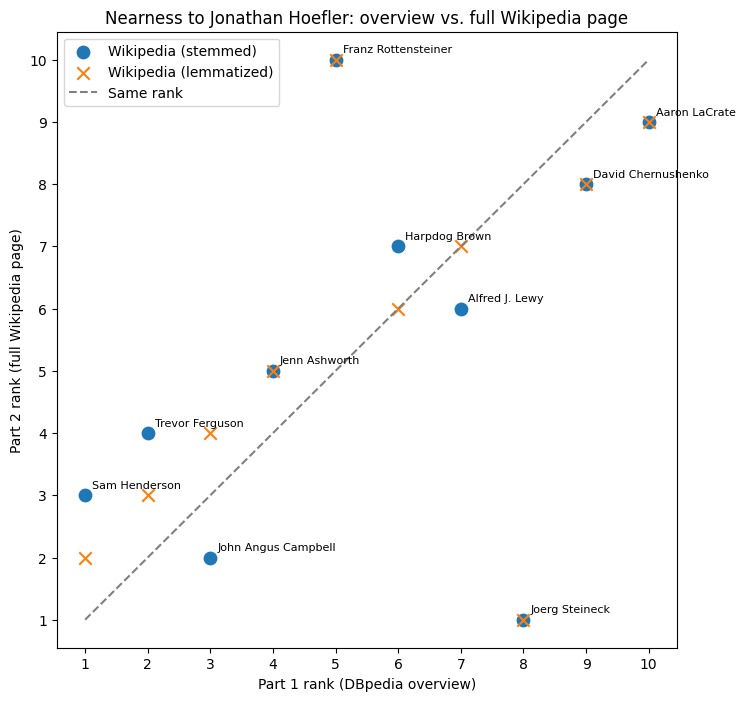

In [38]:
fig, ax = plt.subplots(figsize=(8, 8))

# Each dot is one person: x = Part 1 rank, y = Wikipedia rank
ax.scatter(compare["part1_rank"], compare["wiki_rank_stem"],  label="Wikipedia (stemmed)",    s=80)
ax.scatter(compare["part1_rank"], compare["wiki_rank_lemma"], label="Wikipedia (lemmatized)", s=80, marker="x")

# Label the stemmed dots with names
for _, row in compare.iterrows():
    ax.annotate(row["name"], (row["part1_rank"], row["wiki_rank_stem"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

# Dashed line = "same rank both ways". Dots far from it changed the most.
ax.plot([1, 10], [1, 10], linestyle="--", color="gray", label="Same rank")

ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel("Part 1 rank (DBpedia overview)")
ax.set_ylabel("Part 2 rank (full Wikipedia page)")
ax.set_title("Nearness to Jonathan Hoefler: overview vs. full Wikipedia page")
ax.legend()
plt.show()